In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from collections import Counter
import os
import time
import ast
from scipy.stats import randint

In [2]:
from tools import read_dag_file, add_risk_parameters, compute_topological_indicators, visualize_dag

In [3]:
sns.set_theme(palette='tab10',style='whitegrid',font='sans-serif')

## DT Dataset (Vanhoucke 2015)
The datasets **DC1** and **DC2** described in the paper by Vanhoucke et al. (2016) are artificial static datasets designed for research on the **Resource-Constrained Project Scheduling Problem with Discounted Cash flows (RCPSPDC)**. The dataset contains projects from 10 to 100 activities randomly generated.

References:
- Vanhoucke, M., Coelho, J., & Batselier, J. (2016). An overview of project data for integrated project management and control. The Journal of Modern Project Management, 3(3), 158-158.
- [Dataset source](https://www.projectmanagement.ugent.be/research/project_scheduling/rcpsp)


**Network Topology parameters** Vanhoucke (2008):
- CNC   Coefficient of Network Complexity
- OS    Order Strength
- I1	Number of activities	
- SP	Serial-Parallel Network Indicator	
- AD	Activity distribution Indicator	
- LA	Length arcs indicator	
- I5	I5 indicator	
- TF	Total float indicator	

In [4]:
# Metadata
df_metadata = pd.read_csv('data/dc_dataset_metadata.txt', sep='\t')

In [6]:
topological_index=['#Act','CNC', 'OS','SP','AD','LA','I5','TF']

Project file: rcpspdc61.rcp

Topological metrics by Vanhoucke
      #Act   CNC   OS    SP    AD    LA    I5    TF
1860    25  2.56  0.5  0.21  0.28  0.13  0.71  0.34

Topological metrics by own calculation
I1: 25, CNC: 2.5600, OS: 0.5000, SP: 0.2083, AD: 0.2842, LA: 0.1324, I5: 0.7111, TF: 0.3368

AON of the project


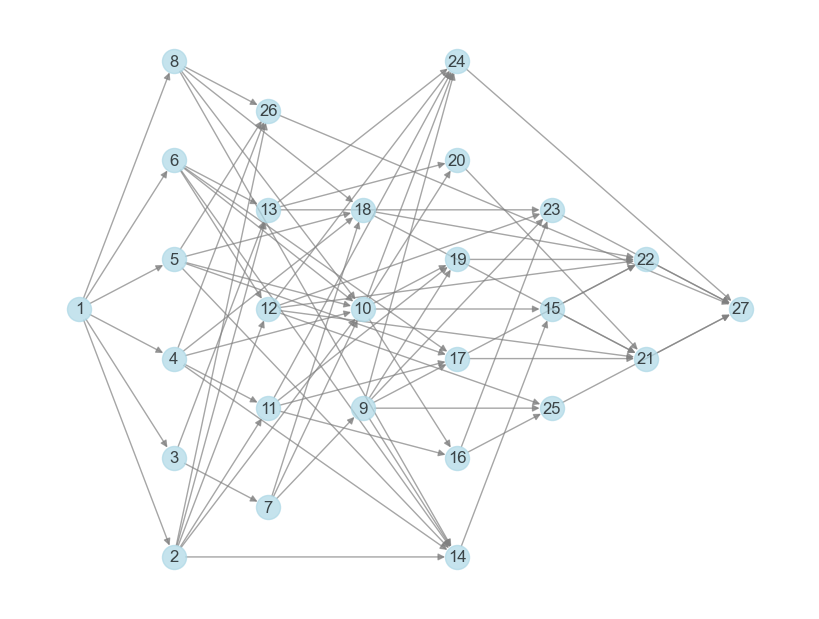

In [10]:
# Check own calculation of topological indices
id=df_metadata.sample(1).index
file=df_metadata.loc[id,'FileName'].values[0]
if '\\' in file:
    file = file.split('\\')[1]
print(f"Project file: {file}")
print("\nTopological metrics by Vanhoucke")
print(df_metadata.loc[id,topological_index])
G = read_dag_file(f"data\DC_all\{file}")
print("\nTopological metrics by own calculation")
I1, CNC, OS, SP, AD, LA, I5, TF= compute_topological_indicators(G)
print(f"I1: {I1}, CNC: {CNC:0.4f}, OS: {OS:0.4f}, SP: {SP:0.4f}, AD: {AD:0.4f}, LA: {LA:0.4f}, I5: {I5:0.4f}, TF: {TF:0.4f}")
print(f"\nAON of the project")
visualize_dag(G)


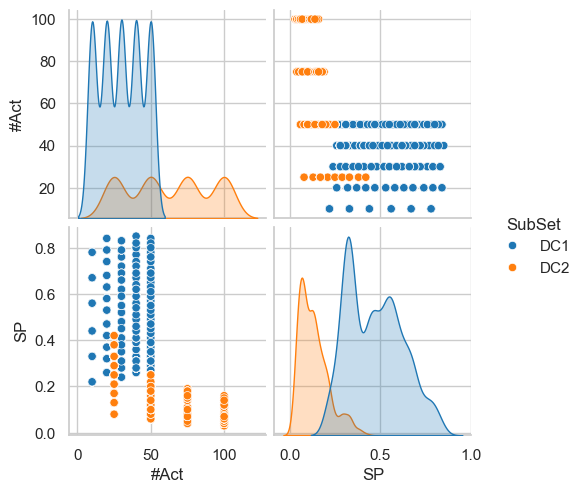

In [11]:
sns.pairplot(df_metadata[['#Act','SP','SubSet']],hue='SubSet')

## PSPLIB dataset
A classical benchmark for RCPSP problems

Kolisch, R., & Sprecher, A. (1997). PSPLIB-a project scheduling problem library: OR software-ORSEP operations research software exchange program. European journal of operational research, 96(1), 205-216.

In [22]:
# Metadata
psplib_metadata = pd.read_csv('data/pslib_dataset_metadata.txt', sep='\t')

In [23]:
psplib_metadata.columns

Index(['ID', 'ID set', 'SetName', 'SubSet', 'FileName', '#Act', 'CNC', 'OS',
       'SP', 'AD',
       ...
       'LB-LPA12-1h', 'MH-SB-1m', 'MH-SB-10m', 'MH-SB-1h', 'MH-PB-1m',
       'MH-PB-10m', 'MH-PB-1h', 'MH-TBI-1m', 'MH-TBI-10m', 'MH-TBI-1h'],
      dtype='object', length=410)

In [24]:
psplib_metadata[['SubSet','FileName']].groupby('SubSet').count()

,FileName
SubSet,
J120,600
J30,480
J60,480
J90,480


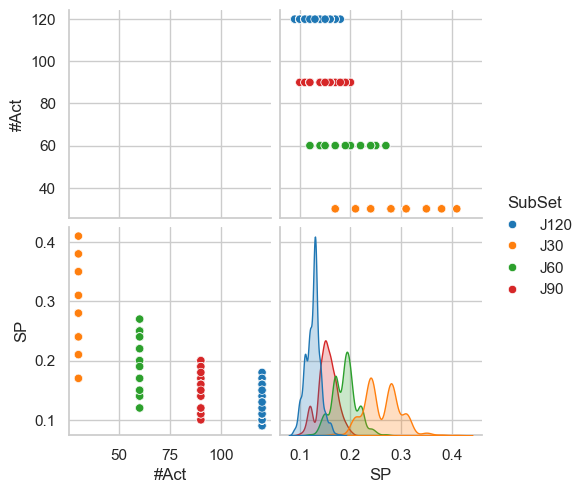

In [25]:
sns.pairplot(psplib_metadata[['#Act','SP','SubSet']],hue='SubSet')

## RanGen2 dataset

In [12]:
data=[]
for i,file in enumerate([f for f in os.listdir('data\\rangen') if f.endswith('.rcp')]):
    dt={}
    dt['FileName']=file
    G = read_dag_file(f"data\\rangen\{file}")
    I1, CNC, OS, SP, AD, LA, I5, TF= compute_topological_indicators(G)
    dt['I1']=I1
    dt['CNC']=CNC
    dt['OS']=OS
    dt['SP']=SP
    dt['AD']=AD
    dt['LA']=LA
    dt['I5']=I5 
    dt['TF']=TF
    data.append(dt)
df_rangen=pd.DataFrame(data)


In [13]:
df_rangen.head(2)

,FileName,I1,CNC,OS,SP,AD,LA,I5,TF
0,Pat1.rcp,20,0.45,0.047368,0.052632,0.444444,0.038462,1.0,0.611111
1,Pat10.rcp,20,0.55,0.057895,0.052632,0.222222,0.034091,1.0,0.444444


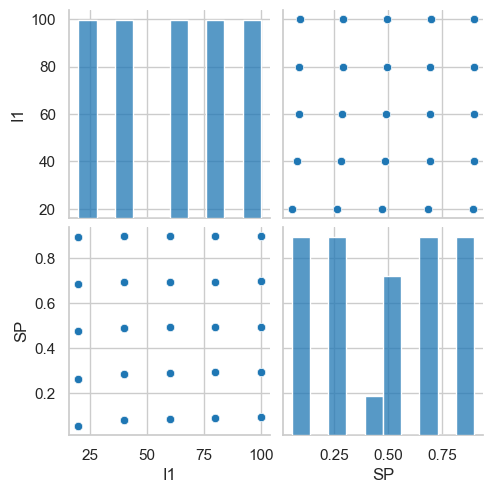

In [14]:
sns.pairplot(df_rangen[['I1','SP']])

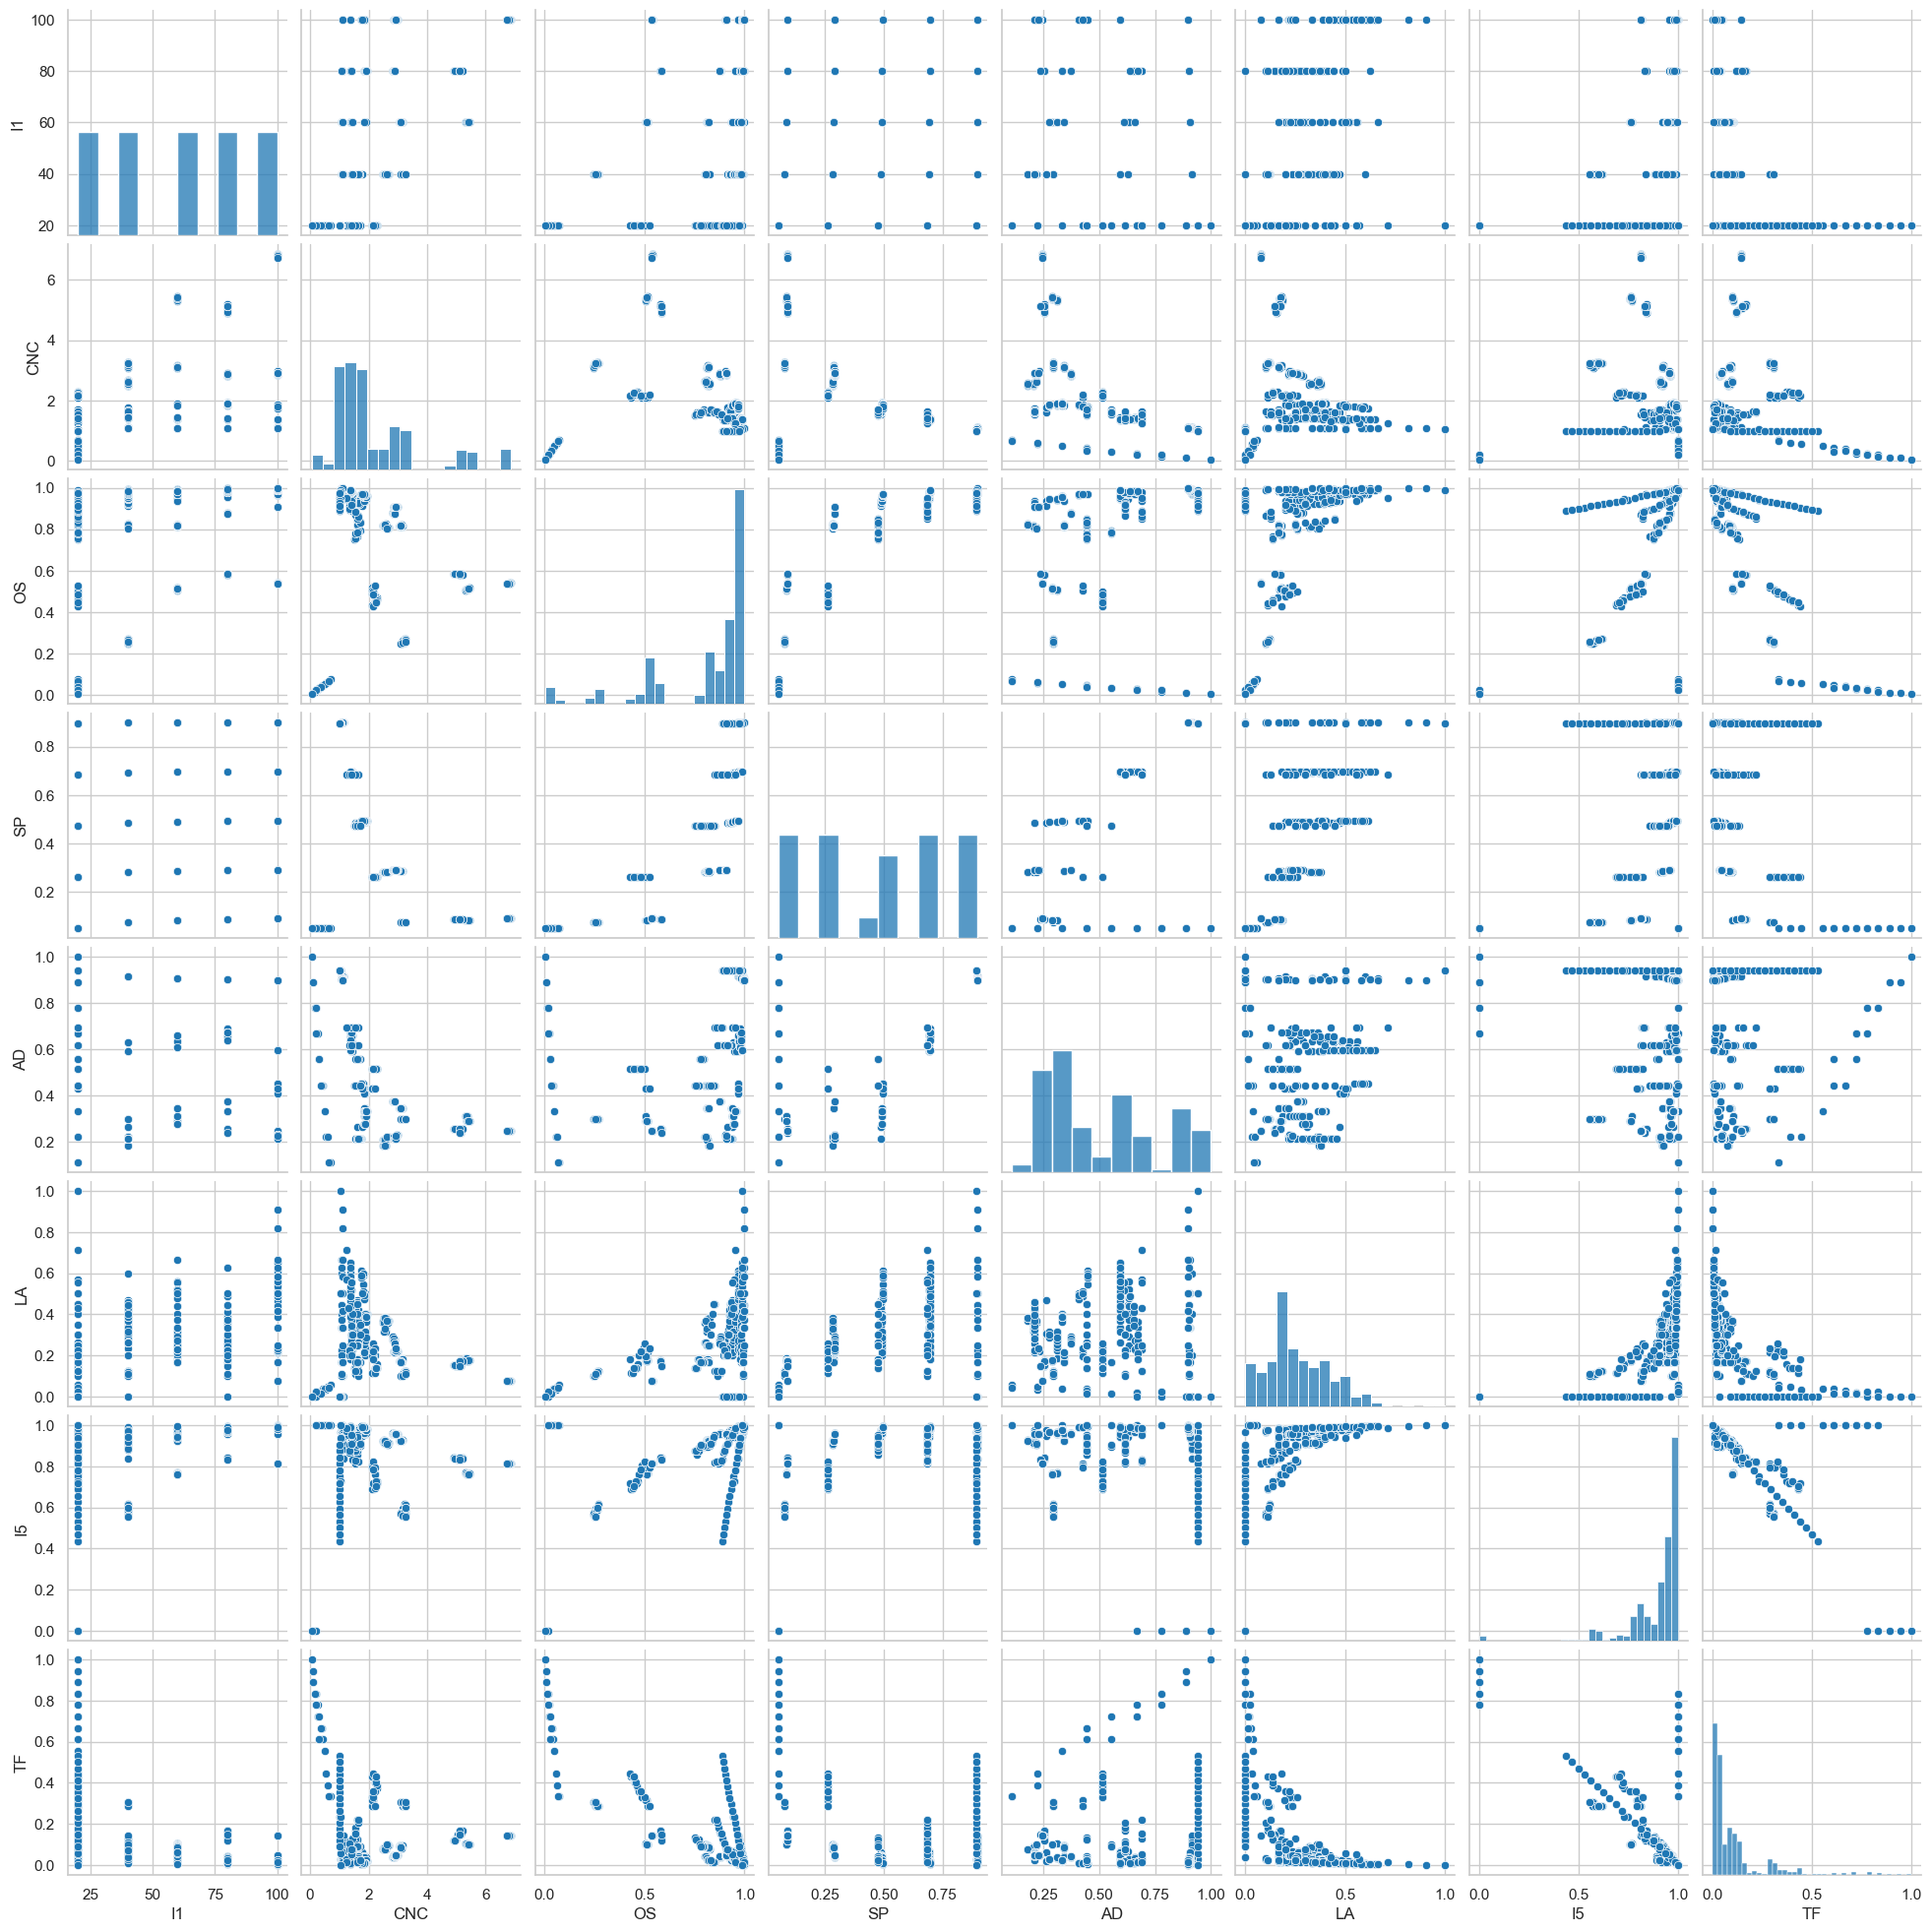

In [16]:
sns.pairplot(df_rangen[['I1','CNC','OS','SP','AD','LA','I5','TF']])